In [19]:
from __future__ import annotations

import argparse
from pathlib import Path
import random
from cbir import (
    DeepFeatureExtractor,
    FeatureGallery,
    HistogramFeatureExtractor,
    plot_search_results,
)

In [20]:
def _image_paths(root: Path) -> list[Path]:
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    return sorted(
        path
        for path in root.glob("*/*")
        if path.is_file() and path.suffix.lower() in extensions
    )

dataset = Path("dataset")
gallery_paths = _image_paths(dataset / "gallery")
if not gallery_paths:
    raise FileNotFoundError(
        "未找到检索库图片，请检查 dataset/gallery 下是否按类别分目录。"
    )

query_paths = _image_paths(dataset / "query")
random.shuffle(query_paths)

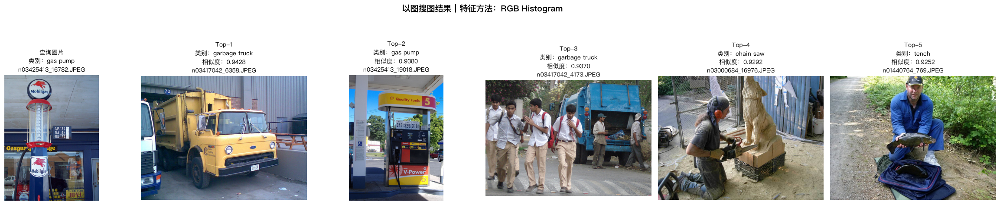

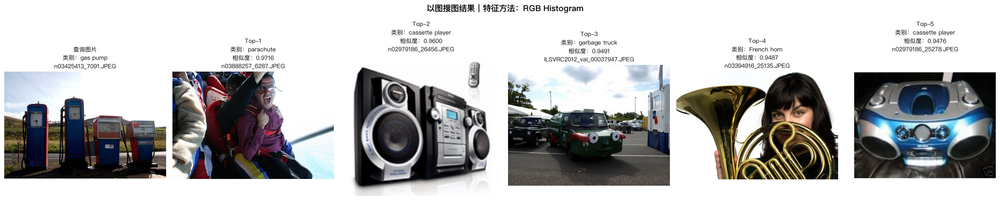

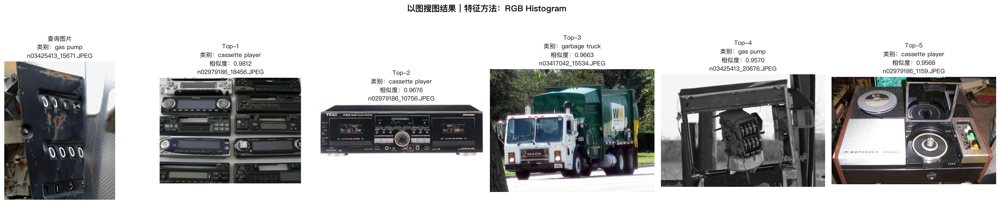

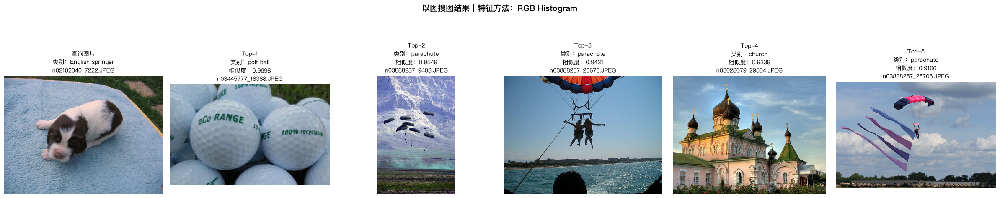

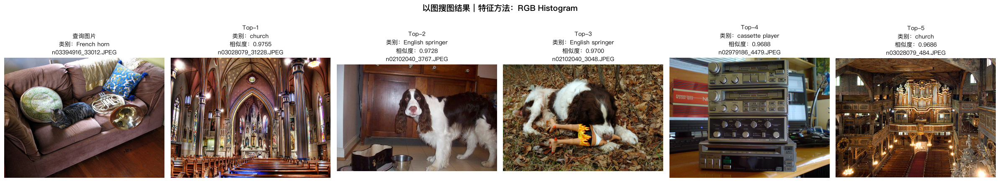

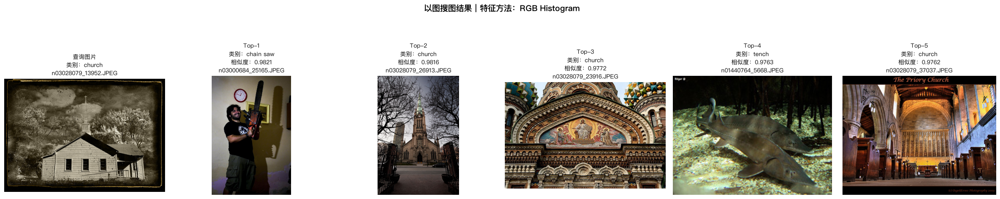

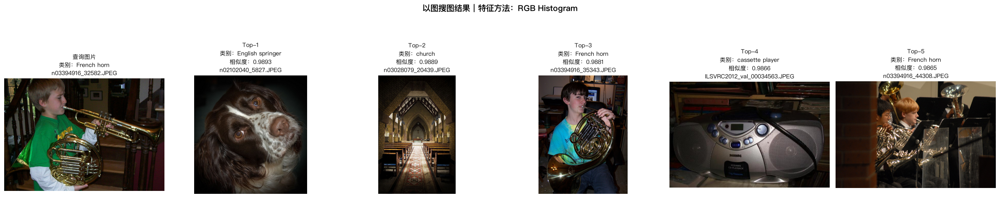

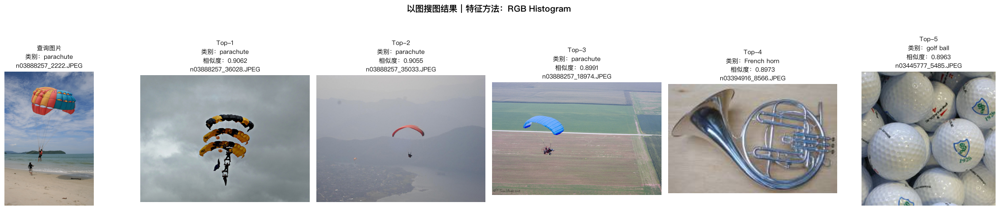

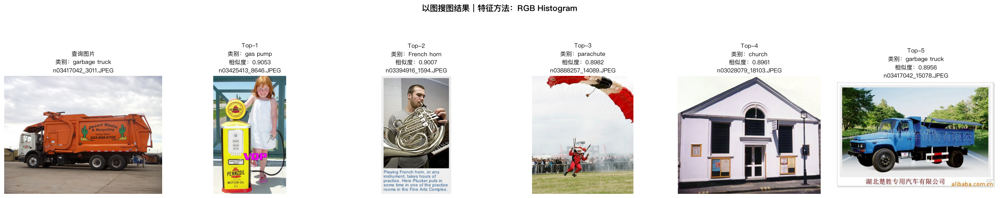

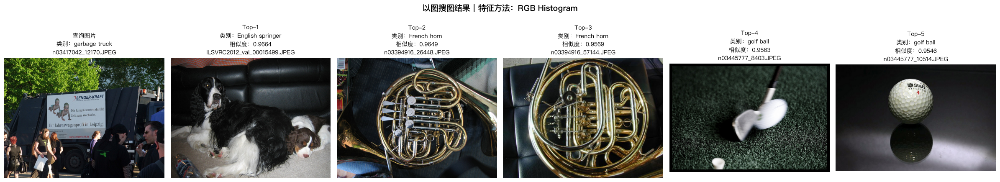

In [21]:
def histogram_retrieval(query_path):
    his_extractor = HistogramFeatureExtractor(bins_per_channel=16)
    cache_path = Path("cache/histogram_gallery.npz")

    his_gallery = FeatureGallery.build_or_load(
        gallery_paths,
        his_extractor,
        cache_path=cache_path,
        categories=[path.parent.name for path in gallery_paths],
    )
    query_feature = his_extractor.extract(query_path)
    results = his_gallery.search(query_feature, top_k=5)
    plot_search_results(
        query_path=query_path,
        results=results,
        feature_method="RGB Histogram",
        query_category=query_path.parent.name
)

for query_path in query_paths[:10]:
    histogram_retrieval(query_path)

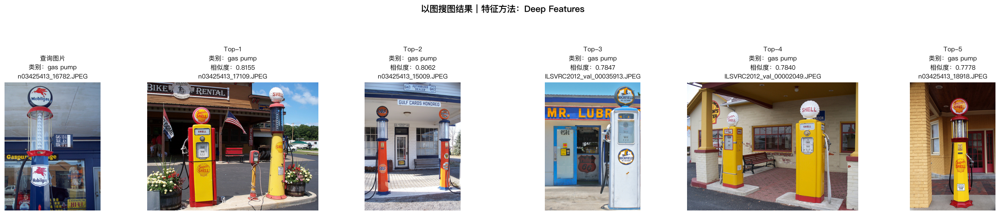

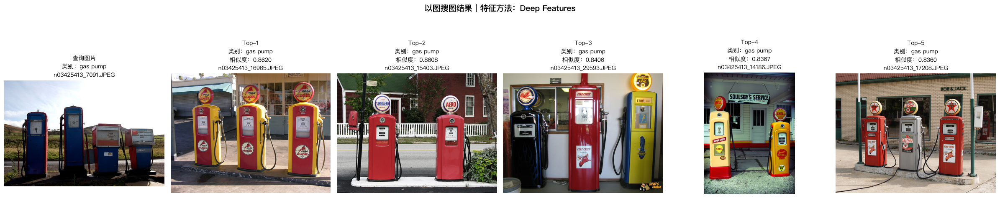

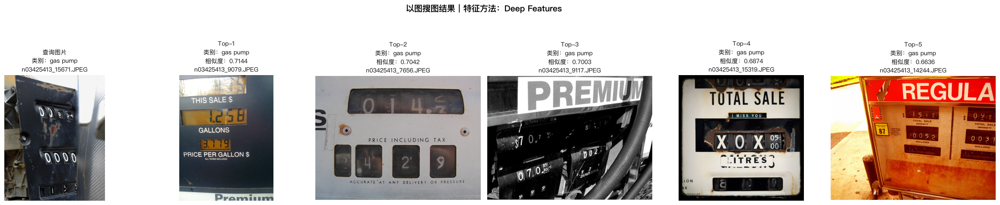

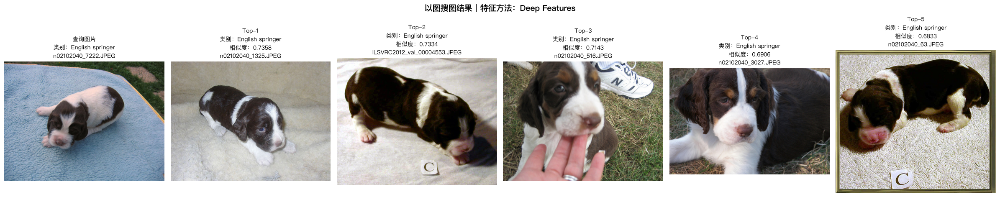

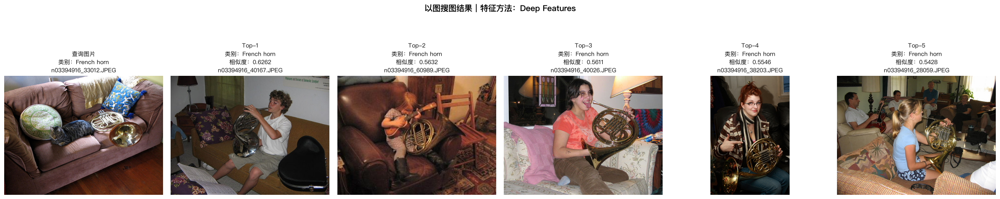

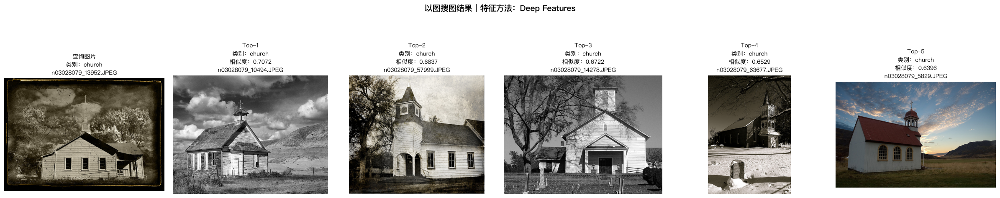

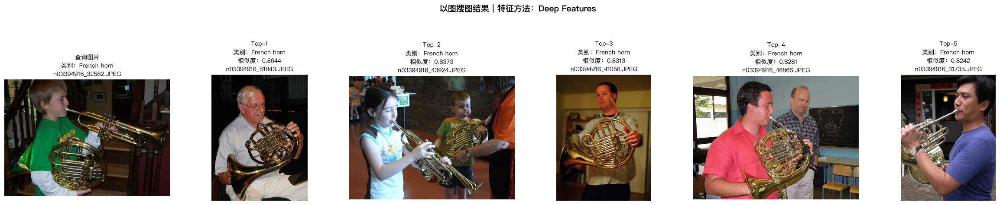

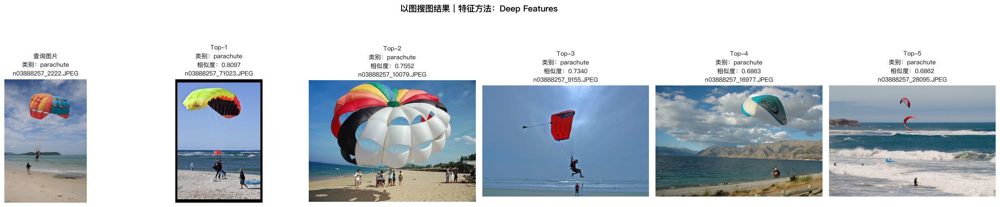

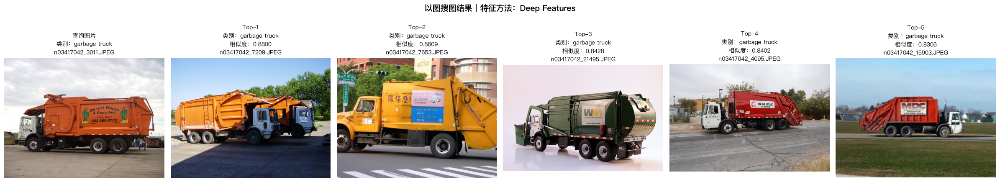

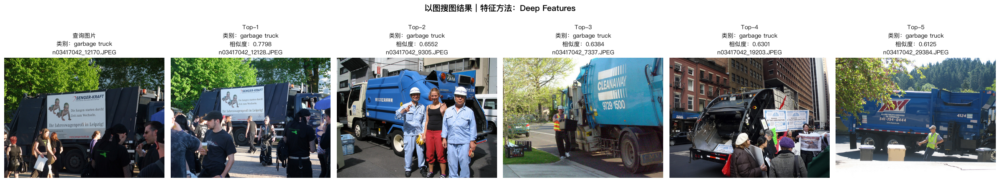

In [22]:
def deepfeature_retrieval(query_path):
    df_extractor = DeepFeatureExtractor()
    df_cache_path = Path("cache/deep_gallery.npz")

    df_gallery = FeatureGallery.build_or_load(
        gallery_paths,
        df_extractor,
        cache_path=df_cache_path,
        categories=[path.parent.name for path in gallery_paths],
    )
    query_feature = df_extractor.extract(query_path)
    results = df_gallery.search(query_feature, top_k=5)
    plot_search_results(
        query_path=query_path,
        results=results,
        feature_method="Deep Features",
        query_category=query_path.parent.name
    )

for query_path in query_paths[:10]:
    deepfeature_retrieval(query_path)